# Time Resolution

In [77]:
import sys
sys.path.append("../")
from lib.histo import *
import matplotlib.pyplot as plt

import numpy as np  

ROOT.gErrorIgnoreLevel = ROOT.kError # Ignore info messages

### Picchi gaussiani

In [19]:
hist_1,c = load_hist("../data/time_res_1ns.root",2,nbins=260,rangemin=400,rangemax=660,draw=True)
c = gaus_fit(hist_1, 490, 590)

A = 2620.3 ± 15.2   μ = 541.85 ± 0.11     σ = 17.82 ± 0.16
Background lineare: q = 1887.63 ± 100.00   m = -0.99274 ± 0.18712


Warning in <TROOT::Append>: Replacing existing TH1: hist (Potential memory leak).
Warning in <TCanvas::Constructor>: Deleting canvas with same name: c1
Warning in <TCanvas::Constructor>: Deleting canvas with same name: c1


In [20]:
hist_3,c = load_hist("../data/time_res_3ns.root",2,nbins=100,rangemin=460,rangemax=560,draw=False)
c = gaus_fit(hist_3, 490, 540)

A = 13240.2 ± 33.0   μ = 514.39 ± 0.03     σ = 9.24 ± 0.03
Background lineare: q = -7718.04 ± 302.90   m = 16.47725 ± 0.58738


Warning in <TROOT::Append>: Replacing existing TH1: hist (Potential memory leak).
Warning in <TCanvas::Constructor>: Deleting canvas with same name: c1


In [21]:
hist_5,c = load_hist("../data/time_res_5ns.root",2,nbins=100,rangemin=460,rangemax=560,draw=False)
c = gaus_fit(hist_5, 490, 530)

A = 10643.6 ± 65.1   μ = 513.78 ± 0.05     σ = 7.80 ± 0.06
Background lineare: q = -53973.16 ± 1232.97   m = 110.91936 ± 2.52053


Warning in <TROOT::Append>: Replacing existing TH1: hist (Potential memory leak).
Warning in <TCanvas::Constructor>: Deleting canvas with same name: c1


In [22]:
hist_4,c = load_hist("../data/time_res_4ns.root",2,nbins=70,rangemin=500,rangemax=570,draw=False)
c = gaus_fit(hist_4, 510, 570)

A = 14129.7 ± 31.6   μ = 536.14 ± 0.02     σ = 9.66 ± 0.02
Background lineare: q = 344.65 ± 211.69   m = 0.00475 ± 0.37483


Warning in <TROOT::Append>: Replacing existing TH1: hist (Potential memory leak).
Warning in <TCanvas::Constructor>: Deleting canvas with same name: c1


In [23]:
hist_8,c = load_hist("../data/time_res_8ns.root",2,nbins=100,rangemin=460,rangemax=560,draw=False)
c = gaus_fit(hist_8, 470, 540)

A = 11546.6 ± 28.9   μ = 506.92 ± 0.02     σ = 10.28 ± 0.03
Background lineare: q = -7462.76 ± 118.46   m = 16.34942 ± 0.24661


Warning in <TROOT::Append>: Replacing existing TH1: hist (Potential memory leak).
Warning in <TCanvas::Constructor>: Deleting canvas with same name: c1


Cavi - delay:  
100cm->5ns. 
80cm->4ns. 
60->3ns. 

In [24]:
x_vals = array('d', [1, 3, 4, 5, 8])
y_vals = np.array([FWHM(hist_1)[0],
    FWHM(hist_3)[0],
    FWHM(hist_4)[0],
    FWHM(hist_5)[0],
    FWHM(hist_8)[0]], dtype=float)

graph = ROOT.TGraph(len(x_vals), x_vals, y_vals)

c1 = ROOT.TCanvas("c1","", 600, 300)
graph.SetMarkerStyle(20)
graph.Draw("AP")
c1.Update()

Warning in <TCanvas::Constructor>: Deleting canvas with same name: c1


### FWHM

In [54]:
def fwhm_linear_fit_with_uncertainty(x, y, half=None, nfit=4, plot=True, distance=None, threshold=None, counts=0, save=True, title="FWHM con fit lineare locale e incertezza"):
    """
    Calcola FWHM usando fit lineare locale su ciascun lato e stima l'incertezza
    dalle matrici di covarianza dei fit lineari.

    Parametri:
      x, y    : arrays (bin centers e counts)
      half    : livello half-max (se None -> max(y)/2)
      nfit    : numero di punti usati per il fit su ciascun lato
      plot    : se True disegna figura con fit
      title   : titolo del grafico

    Ritorna:
      dict con chiavi:
        fwhm, fwhm_err,
        left_x, left_x_err, right_x, right_x_err,
        peak_x, peak_y
      (valori None se non calcolabili)
    """
    x = np.asarray(x, dtype=float)
    y = np.asarray(y, dtype=float)

    # pulizia
    y = np.nan_to_num(y, nan=0.0)

    # trova il picco
    peak_idx = int(np.argmax(y))
    peak_x = float(x[peak_idx])
    peak_y = float(y[peak_idx])

    if half is None:
        half = peak_y / 2.0

    # funzione helper per trovare l'indice di crossing (sinistra) come prima match
    left_k = None
    for k in range(peak_idx-1, -1, -1):
        if (y[k] <= half <= y[k+1]) or (y[k] >= half >= y[k+1]):
            left_k = k
            break

    right_k = None
    for k in range(peak_idx, len(x)-1):
        if (y[k] >= half >= y[k+1]) or (y[k] <= half <= y[k+1]):
            right_k = k
            break

    left_x = left_x_err = right_x = right_x_err = None

    def fit_and_cross(indices):
        """Esegue fit lineare su x[idx], y[idx], ritorna crossing e incertezza"""
        xi = x[indices]
        yi = y[indices]
        # se non ci sono abbastanza punti, ritorna None
        if len(xi) < 2:
            return None, None, None, None
        # fit lineare con np.polyfit restituendo cov
        try:
            p, cov = np.polyfit(xi, yi, 1, cov=True)
        except Exception:
            # fit fallito
            return None, None, None, None
        a, b = p[0], p[1]  # y = a*x + b
        # se a è (quasi) zero, non possiamo risolvere
        if np.isclose(a, 0.0):
            return None, None, p, cov
        # crossing con y = half: x = (half - b)/a
        xcross = (half - b) / a

        # covariance: var(a) = cov[0,0], var(b)=cov[1,1], cov_ab = cov[0,1]
        var_a = cov[0,0]
        var_b = cov[1,1]
        cov_ab = cov[0,1]

        # propagation: x = (half - b)/a
        # dx/da = -(half - b)/a^2 = -xcross / a
        # dx/db = -1/a
        da = -xcross / a
        db = -1.0 / a
        var_x = (da**2) * var_a + (db**2) * var_b + 2.0 * da * db * cov_ab

        # se var_x negative numericamente (rare), proteggiamo
        if var_x < 0:
            var_x = max(var_x, 0.0)

        x_err = np.sqrt(var_x)

        return xcross, x_err, p, cov

    # --- fit lato sinistro: prendo nfit punti che terminano in k+1 (per includere il segmento k,k+1) ---
    if left_k is not None:
        start = max(0, left_k - (nfit - 2))
        end = left_k + 2  # slice python end non incluso -> include index left_k+1
        idx = np.arange(start, end)
        left_x, left_x_err, p_left, cov_left = fit_and_cross(idx)

    # --- fit lato destro: prendo nfit punti che iniziano in k (includo k,k+1) ---
    if right_k is not None:
        start = right_k
        end = min(len(x), right_k + nfit)
        idx = np.arange(start, end)
        right_x, right_x_err, p_right, cov_right = fit_and_cross(idx)

    # FWHM and its uncertainty (assumendo indipendenza left/right)
    fwhm = None
    fwhm_err = None
    if (left_x is not None) and (right_x is not None):
        fwhm = right_x - left_x
        # se abbiamo errs
        if (left_x_err is not None) and (right_x_err is not None):
            fwhm_err = np.sqrt(left_x_err**2 + right_x_err**2)

    if distance is not None:
        print("La FWHM a distanza", distance,"um vale: ", fwhm)
        if save:
            with open('FWHM_vs_distance.txt', 'a') as f:
                print(distance, "\t", fwhm, "\t", fwhm_err, file=f) 

    if threshold is not None:
        print("La FWHM a threshold", threshold,"KeV vale: ", fwhm)
        if save:
            with open('FWHM_vs_threshold.txt', 'a') as f:
                print(threshold, "\t", fwhm, "\t", fwhm_err, "\t", counts, file=f) 

    # plot
    if plot:
        plt.figure(figsize=(8,5))
        plt.plot(x, y, drawstyle="steps-mid", label="istogramma", color='mediumblue')
        plt.fill_between(x, y1=np.zeros_like(x), y2=y, step='mid', color='dodgerblue', alpha=0.3)
        #plt.scatter(x, y, s=20)
        plt.text(0.13, 0.52, "half maximum", transform=plt.gca().transAxes, fontsize=12, fontstyle='italic', weight='bold', color="crimson", ha="center")
        plt.axhline(half, color="crimson", ls="--", label=f"Half max = {half:.3g}")

        # mostra i punti usati per i fit, e le rette di fit
        #if left_k is not None:
        start = max(0, left_k - (nfit - 2)); end = left_k + 2
        idx = np.arange(start, end)
            #plt.scatter(x[idx], y[idx], marker='o', edgecolor='k', facecolor='none', s=80, label="left fit pts")
            #if 'p_left' in locals() and p_left is not None:
        a_l, b_l = p_left[0], p_left[1]
        xs_l = np.linspace(x[idx].min()-15, x[idx].max()+15, 50)
        #plt.plot(xs, a*xs + b, color='C1', linestyle='-', label='left fit')

        # if right_k is not None:
        start = right_k; end = min(len(x), right_k + nfit)
        idx = np.arange(start, end)
        #plt.scatter(x[idx], y[idx], marker='s', edgecolor='k', facecolor='none', s=80, label="right fit pts")
        #if 'p_right' in locals() and p_right is not None:
        a_r, b_r = p_right[0], p_right[1]
        xs_r = np.linspace(x[idx].min()-15, x[idx].max()+15, 50)
        #plt.plot(xs, a*xs + b, color='C2', linestyle='-', label='right fit')

        if left_x is not None:
            plt.vlines(left_x, ymin=0, ymax=half, color='dimgray', ls='--', label=f'left = {left_x:.3g} ± {left_x_err:.3g}')
        if right_x is not None:
            plt.vlines(right_x, ymin=0, ymax=half, color='dimgray', ls='--', label=f'right = {right_x:.3g} ± {right_x_err:.3g}')


        plt.annotate("", xy=(right_x, half/2), xycoords='data',   # punto destro
                    xytext=(left_x, half/2), textcoords='data',   # punto sinistro
                    arrowprops=dict(arrowstyle="<->", color="black", lw=2))
        plt.text((right_x+left_x)/2, half/2.5, "FWHM", fontsize=8, weight='bold', color="black", ha="center")
       
        # if fwhm is not None:
        #     plt.title(f"{title}\nFWHM = {fwhm:.4g} ± {fwhm_err:.4g}" if fwhm_err is not None else f"{title}\nFWHM = {fwhm:.4g}")
        # else:
        #     plt.title(title)

        def fstring_with_error(value, error):
            """
            Restituisce una stringa 'valore ± errore' pronta da usare in f-string,
            arrotondando il valore alla stessa cifra significativa dell'errore.
            """
            if error == 0:
                return f"{value} ± {error}"

            # ordine di grandezza dell'errore
            exponent = int(np.floor(np.log10(abs(error))))
            
            # arrotonda errore e valore
            rounded_error = round(error, -exponent)
            rounded_value = round(value, -exponent)
            
            # numero di cifre decimali per la formattazione
            decimals = max(0, -exponent)
            
            return f"FWHM = {rounded_value:.{decimals}f} ± {rounded_error:.{decimals}f} mm"

        plt.gca().text(
        0.95, 0.95, fstring_with_error(fwhm,fwhm_err) if fwhm_err is not None else f"FWHM = {fwhm:.4g} [mm]",
        transform=plt.gca().transAxes,
        fontsize=11,
        va="top", ha="right",
        bbox=dict(boxstyle="round", facecolor="white", edgecolor="black", linewidth=0.8)
        )

    
        plt.title(title, fontsize=18)
        plt.xlabel("Asse X [mm]", fontsize=14)
        plt.ylabel("Conteggi", fontsize=14)
        #plt.legend(loc='best', fontsize='small')
        plt.grid(alpha=0.25)
        plt.ylim(bottom=0)

        plt.plot(xs_l, a_l*xs_l + b_l, color='red', linestyle='-', label='right fit')
        plt.plot(xs_r, a_r*xs_r + b_r, color='red', linestyle='-', label='right fit')
        plt.show()

    return {
        'fwhm': fwhm,
        'fwhm_err': fwhm_err,
        'left_x': left_x, 'left_x_err': left_x_err,
        'right_x': right_x, 'right_x_err': right_x_err,
        'peak_x': peak_x, 'peak_y': peak_y
    }

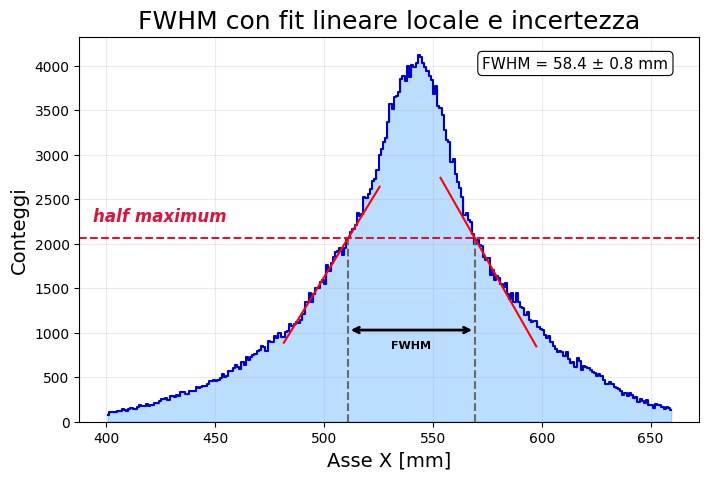

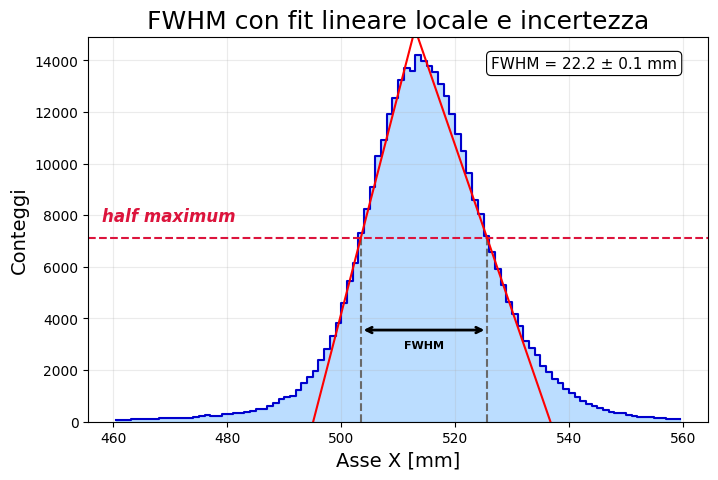

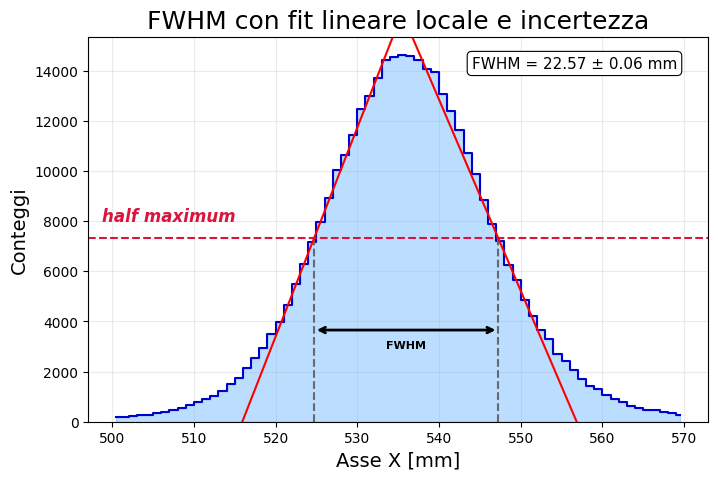

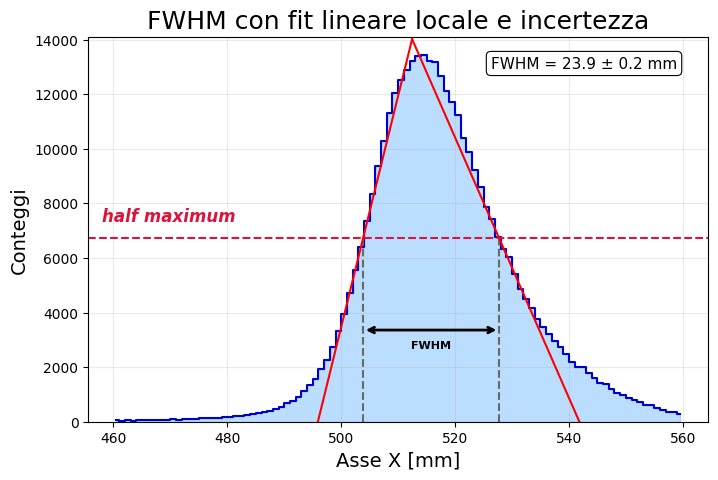

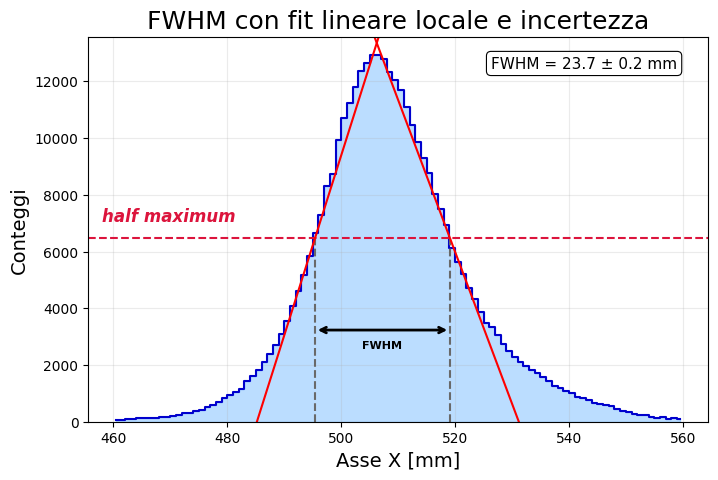

In [73]:
import numpy as np

histos = [hist_1, hist_3, hist_4, hist_5, hist_8]
nfits = [15, 5, 5, 5, 5]

fwhm = np.array([])
fwhm_err = np.array([])

for j in range(len(histos)):
    x = np.array([histos[j].GetBinCenter(i) for i in range(1, histos[j].GetNbinsX()+1)])
    y = np.array([histos[j].GetBinContent(i) for i in range(1, histos[j].GetNbinsX()+1)])

    a = fwhm_linear_fit_with_uncertainty(x,y,nfit=nfits[j],plot=True)
    fwhm = np.append(fwhm, a['fwhm'])
    fwhm_err = np.append(fwhm_err, a['fwhm_err'])

# hist = hist_8
# x = np.array([hist.GetBinCenter(i) for i in range(1, hist.GetNbinsX()+1)])
# y = np.array([hist.GetBinContent(i) for i in range(1, hist.GetNbinsX()+1)])

# a = fwhm_linear_fit_with_uncertainty(x,y,nfit=5,plot=True)
# fwhm = np.append(fwhm, a['fwhm'])
# fwhm_err = np.append(fwhm_err, a['fwhm_err'])

In [74]:
print("FWHM values:", fwhm)
print("FWHM uncertainties:", fwhm_err)

time = np.array([1, 3, 4, 5, 8])

FWHM values: [58.37075317 22.22575413 22.56647423 23.92175656 23.73379901]
FWHM uncertainties: [0.81938905 0.11047541 0.06333182 0.17546382 0.19853735]


<ErrorbarContainer object of 3 artists>

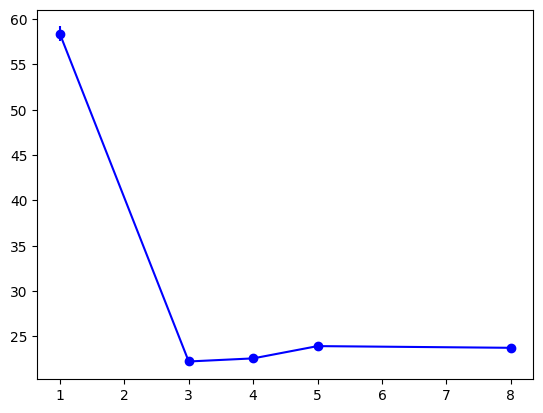

In [75]:
plt.errorbar(time, fwhm, yerr=fwhm_err, marker='o', linestyle='-', color='blue', label='FWHM vs Time Window')

# Cobalto

Scegliamo i 4ns per la presa dati in notturna:

In [29]:
hist_cob0,c0 = load_hist("../data/cob.root",0,nbins=2000,rangemin=0,rangemax=2000,draw=True,multitree=[4,5])

Warning in <TROOT::Append>: Replacing existing TH1: hist (Potential memory leak).
Warning in <TCanvas::Constructor>: Deleting canvas with same name: c1


In [30]:
hist_cob1,c1 = load_hist("../data/cob.root",1,nbins=1000,rangemin=0,rangemax=1000,draw=True,multitree=[4,5])

Warning in <TROOT::Append>: Replacing existing TH1: hist (Potential memory leak).
Warning in <TCanvas::Constructor>: Deleting canvas with same name: c1


In [82]:
hist_cob2,c2 = load_hist("../data/cob.root",2,nbins=80,rangemin=500,rangemax=580,draw=True)
c = gaus_fit(hist_cob2,520,555)

A = 169036.1 ± 152.7   μ = 538.21 ± 0.01     σ = 6.61 ± 0.01
Background lineare: q = -60600.38 ± 2442.65   m = 145.50120 ± 4.61578


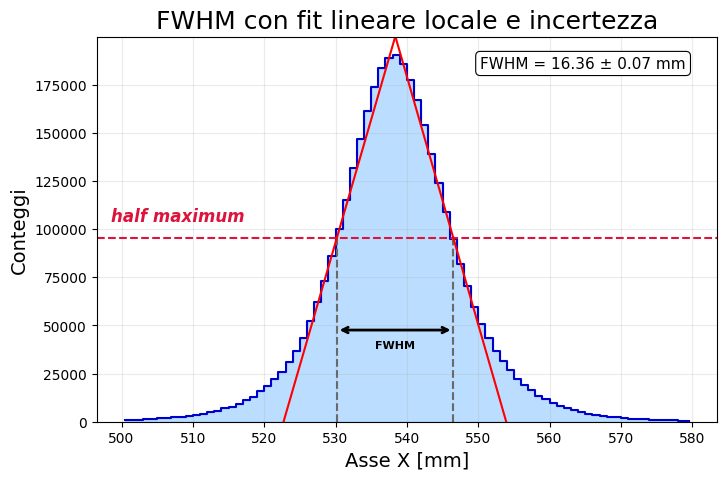

{'fwhm': np.float64(16.362986328566535),
 'fwhm_err': np.float64(0.06616064735681257),
 'left_x': np.float64(530.1623832233106),
 'left_x_err': np.float64(0.0566410714911426),
 'right_x': np.float64(546.5253695518771),
 'right_x_err': np.float64(0.03419093855113928),
 'peak_x': 538.5,
 'peak_y': 190347.0}

In [83]:
x = np.array([hist_cob2.GetBinCenter(i) for i in range(1, hist_cob2.GetNbinsX()+1)])
y = np.array([hist_cob2.GetBinContent(i) for i in range(1, hist_cob2.GetNbinsX()+1)])

fwhm_linear_fit_with_uncertainty(x,y,nfit=4,plot=True)